# 05 · Machine Learning: Predicting Math Proficiency
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**ML task (brief, Option B: Regression).** *Can institutional characteristics help predict a school's math proficiency?*

**Why regression on math proficiency (and not the other options)?**
- The EDA showed math proficiency has real, strong structure that school characteristics relate to, which gives a meaningful modelling problem. The EDA also suggested STEM certification barely differs on observed characteristics, so a classifier would struggle.
- It extends the statistical notebook: regression there *explained* associations; here I test how well the same information *predicts* on schools the model has never seen.

**Contents**
1. Setup and feature selection (including what I deliberately leave out, and why)
2. Train / test split
3. Evaluation metrics: what I measure and why
4. Models and tuning
5. Cross-validated comparison
6. Final evaluation on held-out data
7. Error analysis: where does the model fail?
8. Interpretation: what did the model learn?
9. Ablation: which feature groups add predictive value?
10. Summary and limitations

## 1. Setup and feature selection

In [1]:
import sys, warnings, time
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, partial_dependence

from utils import PATHS, set_style, save_fig, save_json, PALETTE, RANDOM_STATE
from data_cleaning import load_k12
set_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

k12 = load_k12()
TARGET = 'math_proficiency_pct'
print(f'{len(k12):,} K-12 schools | target = {TARGET}')

4,642 K-12 schools | target = math_proficiency_pct


### Which features go in, and which stay out

A model is only as meaningful as its inputs. The **question is about institutional characteristics**, so features must describe a school's *context and resources*, not *other outcomes*. Using one outcome to predict another (for example reading proficiency to predict math) would give a very accurate model that teaches nothing: that is **leakage** (the inputs contain information that is a consequence of, or measures, the thing being predicted).

In [2]:
num_features = ['ppe_k', 'percent_free_reduced_lunch', 'broadband_access_pct', 'student_teacher_ratio',
                'log_enrollment', 'english_learner_pct', 'special_education_pct',
                'federal_funding_pct', 'local_funding_pct']
cat_features = ['level', 'control', 'nces_locale', 'title_i_status']
features = num_features + cat_features

excluded = pd.DataFrame([
    ('reading_proficiency_pct', 'Another academic outcome; near-duplicate of the target (leakage)'),
    ('chronic_absenteeism_pct', 'Outcome / pathway, not a school resource; would blur what the model learns about resources'),
    ('graduation_rate_pct, avg_sat_score, avg_act_score, ap_ib_participation_pct, postsecondary_enrollment_pct',
     'Downstream outcomes, and structurally missing for most schools (notebook 02)'),
    ('state_funding_pct', 'Perfectly determined by federal + local shares (they sum to 100): redundant'),
    ('number_of_teachers', 'Redundant with enrollment and student-teacher ratio'),
    ('racial_*_pct', 'Not used in the main model: weak signal, and predicting school scores from racial composition raises fairness concerns. Tested separately as a sensitivity check in section 9'),
    ('stem_certified_flag', 'A school designation, not a resource or context; also unrelated to the question'),
    ('state_code, county, institution_name / id', 'High-cardinality identifiers; would let the model memorise places'),
], columns=['excluded variable(s)', 'reason'])
display(excluded)
print(f'\nModel inputs: {len(num_features)} numeric + {len(cat_features)} categorical features')

,excluded variable(s),reason
0,reading_proficiency_pct,Another academic outcome; near-duplicate of th...
1,chronic_absenteeism_pct,"Outcome / pathway, not a school resource; woul..."
2,"graduation_rate_pct, avg_sat_score, avg_act_sc...","Downstream outcomes, and structurally missing ..."
3,state_funding_pct,Perfectly determined by federal + local shares...
4,number_of_teachers,Redundant with enrollment and student-teacher ...
5,racial_*_pct,"Not used in the main model: weak signal, and p..."
6,stem_certified_flag,"A school designation, not a resource or contex..."
7,"state_code, county, institution_name / id",High-cardinality identifiers; would let the mo...



Model inputs: 9 numeric + 4 categorical features


**A caution about overlapping features.** Two sets of features overlap heavily, which matters for interpretation (not for prediction):
- Title I status "Not Applicable" coincides *exactly* with private control (every private school is "Not Applicable", no public school is).
- `federal_funding_pct` and `local_funding_pct` are fixed at 0 and 98 for every Private Non-Profit and Private Religious school (notebook 02, section 3.7), so they partly act as stand-ins for public versus private control.

I keep these features because they are legitimate school characteristics, but I do **not** interpret the control, Title I or funding-share coefficients individually (section 8.1).

## 2. Train / test split

I hold out **20% of schools** that the models never see during training or tuning. Their performance is the honest estimate of how well the model would do on new schools. All tuning uses *only* the training portion (via cross-validation), so the test set stays untouched until the end.

In [3]:
X = k12[features]
y = k12[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f'Train: {len(X_train):,} schools | Test: {len(X_test):,} schools')
print(f'Target mean  train = {y_train.mean():.1f}, test = {y_test.mean():.1f}  (similar: the split is representative)')
print(f'Target sd    train = {y_train.std():.1f}, test = {y_test.std():.1f}')

Train: 3,713 schools | Test: 929 schools
Target mean  train = 58.6, test = 58.8  (similar: the split is representative)
Target sd    train = 15.9, test = 16.5


## 3. Evaluation metrics: what I measure and why

| Metric | Meaning | Why it is here |
|---|---|---|
| **RMSE** (primary) | Typical prediction error, in percentage points of proficiency, with large misses penalised more | A stakeholder using this to *flag schools needing attention* cares most about big misses; RMSE punishes them. It is in the same units as the target. |
| **MAE** | Average absolute error | Easy to explain ("on average the prediction is off by X points") and less sensitive to a few extreme errors. |
| **R²** | Share of the variation in math proficiency the model explains | Compares against the trivial "always predict the average" model; makes results comparable with the regression in notebook 04. |

**Baseline.** A model that always predicts the training mean has R² ≈ 0 and an RMSE equal to the standard deviation of the target. Any useful model must beat it.

In [4]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def score(model, X_, y_):
    p = model.predict(X_)
    return {'MAE': mean_absolute_error(y_, p), 'RMSE': rmse(y_, p), 'R2': r2_score(y_, p)}

## 4. Models and tuning

I compare models of increasing complexity, so I can see *whether complexity is actually needed*:

1. **Baseline** (predict the mean): the floor.
2. **Linear regression**: simple, interpretable, directly comparable to the statistical notebook.
3. **Ridge regression**: linear with shrinkage (guards against over-fitting; the penalty is chosen by cross-validation).
4. **Random forest**: many decision trees averaged; captures non-linearities and interactions automatically.
5. **Gradient boosting**: trees built sequentially, each correcting the last; often the strongest tabular model.

Numeric features are standardised for the linear models (needed for a fair ridge penalty); tree models do not need scaling. Categorical features are one-hot encoded. Preprocessing sits **inside** the pipeline so it is fitted only on training data in each cross-validation fold (no leakage).

In [5]:
def make_pre(scale=True):
    num = StandardScaler() if scale else 'passthrough'
    cat = OneHotEncoder(handle_unknown='ignore', drop='first' if scale else None)
    return ColumnTransformer([('num', num, num_features), ('cat', cat, cat_features)])

models = {
    'Baseline (mean)': Pipeline([('pre', make_pre()), ('model', DummyRegressor(strategy='mean'))]),
    'Linear regression': Pipeline([('pre', make_pre()), ('model', LinearRegression())]),
    'Ridge': Pipeline([('pre', make_pre()), ('model', RidgeCV(alphas=np.logspace(-2, 3, 30)))]),
    'Random forest': Pipeline([('pre', make_pre(False)), ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))]),
    'Gradient boosting': Pipeline([('pre', make_pre(False)), ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))]),
}
complexity_order = list(models)  # simplest -> most complex

### Hyperparameter tuning (training data only)
For the two tree models I use **randomised search with 3-fold cross-validation on the training set**. This tests a sample of settings (tree depth, leaf size, learning rate, ...) and keeps the best, which stops the models from simply memorising the training data.

In [6]:
cv_inner = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

searches = {
    'Random forest': (models['Random forest'], {
        'model__n_estimators': [200, 300],
        'model__max_depth': [4, 6, 8, 12, None],
        'model__min_samples_leaf': [5, 10, 20, 40],
        'model__max_features': [0.3, 0.5, 0.8, 1.0],
    }),
    'Gradient boosting': (models['Gradient boosting'], {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [2, 3, 4],
        'model__min_samples_leaf': [10, 20, 40],
        'model__subsample': [0.7, 0.85, 1.0],
    }),
}
best_params = {}
for name, (pipe, grid) in searches.items():
    t0 = time.time()
    rs = RandomizedSearchCV(pipe, grid, n_iter=10, cv=cv_inner, scoring='neg_root_mean_squared_error',
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
    rs.fit(X_train, y_train)
    models[name] = rs.best_estimator_
    best_params[name] = {k.replace('model__', ''): v for k, v in rs.best_params_.items()}
    print(f'{name}: tuned in {time.time() - t0:.0f}s | best CV RMSE = {-rs.best_score_:.2f}')
    print('   best settings:', best_params[name])

# The untuned models are simply fitted on the full training set.
for name in ['Baseline (mean)', 'Linear regression', 'Ridge']:
    models[name].fit(X_train, y_train)
print(f"\nRidge penalty chosen by cross-validation: alpha = {models['Ridge'].named_steps['model'].alpha_:.2f}")

Random forest: tuned in 36s | best CV RMSE = 12.64
   best settings: {'n_estimators': 300, 'min_samples_leaf': 40, 'max_features': 0.8, 'max_depth': 6}


Gradient boosting: tuned in 36s | best CV RMSE = 12.63
   best settings: {'subsample': 0.7, 'n_estimators': 300, 'min_samples_leaf': 40, 'max_depth': 2, 'learning_rate': 0.02}



Ridge penalty chosen by cross-validation: alpha = 62.10


## 5. Cross-validated comparison

Five-fold cross-validation on the training set gives a stable estimate of each model's error *and how much it varies from fold to fold*, which a single split cannot show.

In [7]:
cv_outer = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

cv_rows = {}
for name, mdl in models.items():
    res = cross_validate(mdl, X_train, y_train, cv=cv_outer, scoring=scoring, n_jobs=1)
    cv_rows[name] = {
        'CV_R2': res['test_r2'].mean(), 'CV_R2_sd': res['test_r2'].std(),
        'CV_MAE': -res['test_mae'].mean(),
        'CV_RMSE': -res['test_rmse'].mean(), 'CV_RMSE_sd': res['test_rmse'].std(),
    }
cv_tbl = pd.DataFrame(cv_rows).T
display(cv_tbl.round(3))

,CV_R2,CV_R2_sd,CV_MAE,CV_RMSE,CV_RMSE_sd
Baseline (mean),-0.001,0.001,12.916,15.941,0.262
Linear regression,0.379,0.012,10.117,12.559,0.302
Ridge,0.379,0.011,10.110,12.552,0.290
Random forest,0.375,0.015,10.160,12.599,0.293
Gradient boosting,0.376,0.016,10.152,12.586,0.316


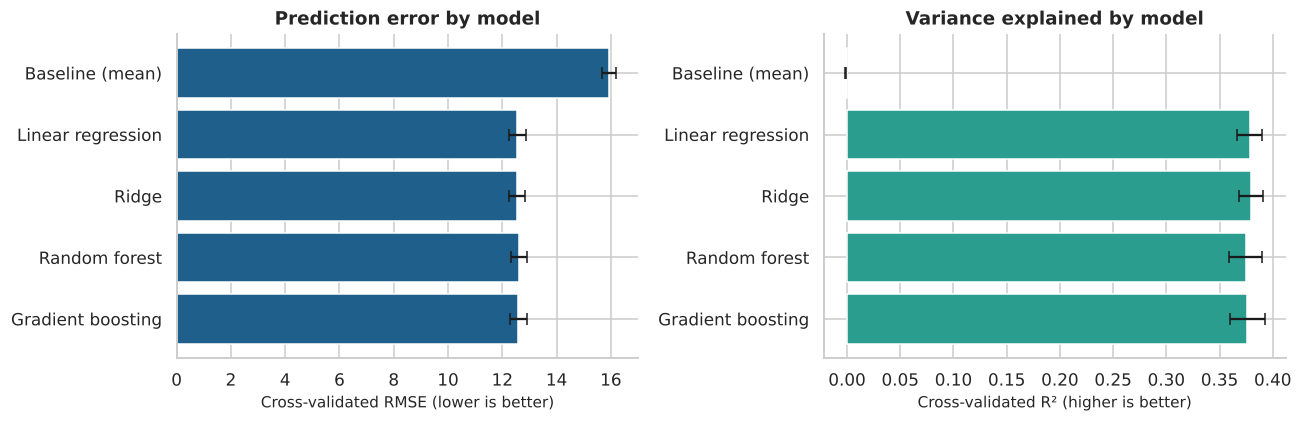

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = cv_tbl.index.tolist()
ax[0].barh(order, cv_tbl['CV_RMSE'], xerr=cv_tbl['CV_RMSE_sd'], color=PALETTE['primary'], capsize=4)
ax[0].set_xlabel('Cross-validated RMSE (lower is better)'); ax[0].set_title('Prediction error by model'); ax[0].invert_yaxis()
ax[1].barh(order, cv_tbl['CV_R2'], xerr=cv_tbl['CV_R2_sd'], color=PALETTE['good'], capsize=4)
ax[1].set_xlabel('Cross-validated R² (higher is better)'); ax[1].set_title('Variance explained by model'); ax[1].invert_yaxis()
plt.tight_layout(); save_fig('05_cv_model_comparison'); plt.show()

**What cross-validation is for here.** Cross-validation on the *training* set is used for model **selection and tuning** only. Because the same folds help choose the settings, its scores can be slightly optimistic. The held-out **test set** (section 6), which no choice ever touched, is the unbiased check.

### Choosing the final model: the one-standard-error rule
The most complex model is not automatically the best choice. A common, defensible rule is: **pick the simplest model whose cross-validated error is within one standard error of the best model's error.** If a simple model is statistically as good as a complex one, the simple one is easier to explain, audit and trust, which matters when the output informs funding decisions.

In [9]:
cands = cv_tbl.drop(index='Baseline (mean)')
best_name = cands['CV_RMSE'].idxmin()
se_best = cands.loc[best_name, 'CV_RMSE_sd'] / np.sqrt(5)
threshold = cands.loc[best_name, 'CV_RMSE'] + se_best

eligible = [m for m in complexity_order if m in cands.index and cands.loc[m, 'CV_RMSE'] <= threshold]
selected = eligible[0]   # simplest eligible model

print(f'Lowest CV RMSE            : {best_name} ({cands.loc[best_name, "CV_RMSE"]:.3f})')
print(f'One-standard-error limit  : {threshold:.3f}')
print(f'Models within the limit   : {eligible}')
print(f'\n==> SELECTED MODEL: {selected}  (simplest model statistically tied with the best)')

Lowest CV RMSE            : Ridge (12.552)
One-standard-error limit  : 12.682
Models within the limit   : ['Linear regression', 'Ridge', 'Random forest', 'Gradient boosting']

==> SELECTED MODEL: Linear regression  (simplest model statistically tied with the best)


## 6. Final evaluation on held-out test data

Now, and only now, the test set is used. Every model is scored once on schools it has never seen.

In [10]:
test_rows = {name: score(mdl, X_test, y_test) for name, mdl in models.items()}
test_tbl = pd.DataFrame(test_rows).T
test_tbl['selected'] = ['<-- selected' if n == selected else '' for n in test_tbl.index]
display(test_tbl.round(3))

sel_model = models[selected]
base = test_rows['Baseline (mean)']; sel = test_rows[selected]
print(f"\nSelected model on unseen schools: R² = {sel['R2']:.3f}, RMSE = {sel['RMSE']:.2f} pts, MAE = {sel['MAE']:.2f} pts")
print(f"Baseline (predict the mean)     : R² = {base['R2']:.3f}, RMSE = {base['RMSE']:.2f} pts")
print(f"Improvement over baseline       : RMSE down by {base['RMSE'] - sel['RMSE']:.2f} pts ({(base['RMSE'] - sel['RMSE']) / base['RMSE']:.0%})")

,MAE,RMSE,R2,selected
Baseline (mean),13.343,16.472,-0.000,
Linear regression,11.055,13.699,0.308,<-- selected
Ridge,11.047,13.687,0.310,
Random forest,11.146,13.797,0.298,
Gradient boosting,11.099,13.737,0.304,



Selected model on unseen schools: R² = 0.308, RMSE = 13.70 pts, MAE = 11.06 pts
Baseline (predict the mean)     : R² = -0.000, RMSE = 16.47 pts
Improvement over baseline       : RMSE down by 2.77 pts (17%)


**Reading the results.** The models clearly beat the baseline, so school characteristics carry real predictive information. Notice, however, how close the linear, ridge and tree-based models are to one another: the flexible models find **little extra signal beyond what a simple linear model already captures**. That tells me the relationships in this data are mostly additive and roughly linear (consistent with the regression diagnostics in notebook 04), and that the limit on accuracy is **not the algorithm but the information available**. No model can predict what the data do not contain (teaching quality, curriculum, local context).

In [11]:
# How stable is the test score? Resample the 929 test schools with replacement and recompute the metrics.
rng = np.random.default_rng(RANDOM_STATE)
p_test = sel_model.predict(X_test)
yt = y_test.values
boot_r2, boot_rmse = [], []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    boot_r2.append(r2_score(yt[idx], p_test[idx])); boot_rmse.append(rmse(yt[idx], p_test[idx]))
test_ci = {'r2': [float(np.percentile(boot_r2, 2.5)), float(np.percentile(boot_r2, 97.5))],
           'rmse': [float(np.percentile(boot_rmse, 2.5)), float(np.percentile(boot_rmse, 97.5))]}
print(f"Test R²   95% bootstrap interval: {test_ci['r2'][0]:.3f} to {test_ci['r2'][1]:.3f}")
print(f"Test RMSE 95% bootstrap interval: {test_ci['rmse'][0]:.2f} to {test_ci['rmse'][1]:.2f} pts")
print(f"Cross-validated R² (training data) was {cv_tbl.loc[selected, 'CV_R2']:.3f}")

Test R²   95% bootstrap interval: 0.254 to 0.356
Test RMSE 95% bootstrap interval: 13.14 to 14.26 pts
Cross-validated R² (training data) was 0.379


Repeated 5-fold CV (10 repeats, all K-12 schools): R² = 0.363 (sd 0.028)
100 random 80/20 splits: mean R² = 0.359; middle 90% of splits: 0.322 to 0.402
The seed-42 test split above scored R² = 0.308


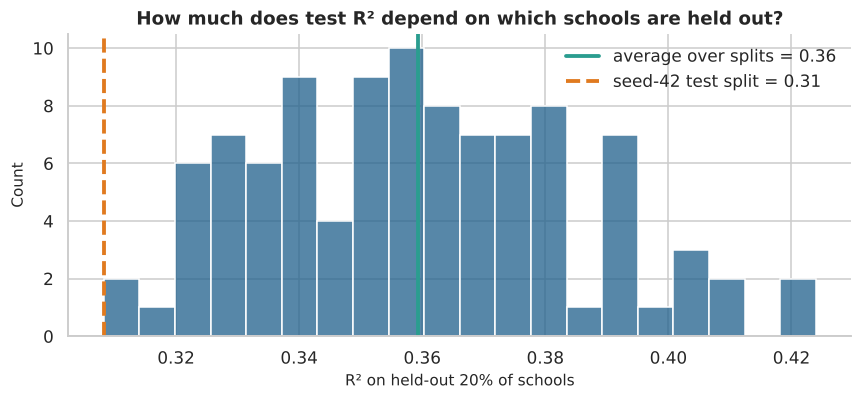

In [12]:
# HEADLINE performance estimate: repeated cross-validation on all K-12 schools.
# The linear model has no tuned hyperparameters, so this is a fair estimate of performance on new schools,
# and averaging over many different splits removes the luck of any single split.
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, ShuffleSplit, cross_val_score

est = clone(models[selected])
rcv = cross_val_score(est, X, y, cv=RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE), scoring='r2')
spl = cross_val_score(est, X, y, cv=ShuffleSplit(n_splits=100, test_size=0.20, random_state=RANDOM_STATE), scoring='r2')
headline = {'repeated_cv_r2_mean': float(rcv.mean()), 'repeated_cv_r2_sd': float(rcv.std()),
            'splits_r2_mean': float(spl.mean()), 'splits_r2_p5': float(np.percentile(spl, 5)),
            'splits_r2_p95': float(np.percentile(spl, 95)), 'seed_test_r2': float(sel['R2'])}
print(f"Repeated 5-fold CV (10 repeats, all K-12 schools): R² = {rcv.mean():.3f} (sd {rcv.std():.3f})")
print(f"100 random 80/20 splits: mean R² = {spl.mean():.3f}; middle 90% of splits: {headline['splits_r2_p5']:.3f} to {headline['splits_r2_p95']:.3f}")
print(f"The seed-42 test split above scored R² = {sel['R2']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(spl, bins=20, color=PALETTE['primary'], ax=ax)
ax.axvline(spl.mean(), color=PALETTE['good'], lw=2.5, label=f'average over splits = {spl.mean():.2f}')
ax.axvline(sel['R2'], color=PALETTE['accent'], lw=2.5, ls='--', label=f'seed-42 test split = {sel["R2"]:.2f}')
ax.set_xlabel('R² on held-out 20% of schools'); ax.set_title('How much does test R² depend on which schools are held out?')
ax.legend(frameon=False); plt.tight_layout(); save_fig('05_r2_across_splits'); plt.show()

**Which R² is the headline?** The seed-42 test score above (about 0.31) comes from **one** particular 80/20 split, and the plot shows it sits at the low end of what different splits produce. A single split of about 930 schools is a noisy yardstick, so my **headline estimate is the repeated cross-validation R², about 0.36** (with a spread of about 0.03 across repeats). I still report the 0.31 seed-42 test score, with its bootstrap interval, because it is the one pre-specified held-out check. Both say the same thing: school characteristics explain roughly **a third** of the variation in math proficiency, not most of it.

The tuned tree models also chose very **shallow, heavily regularised** settings (see the printed best settings above, such as depth-2 trees in boosting). Flexible models asking for that much restraint is another sign the signal in this data is simple and mostly linear.

## 7. Error analysis: where does the model fail?

An overall score can hide systematic weaknesses. I check whether the errors are balanced across school types.

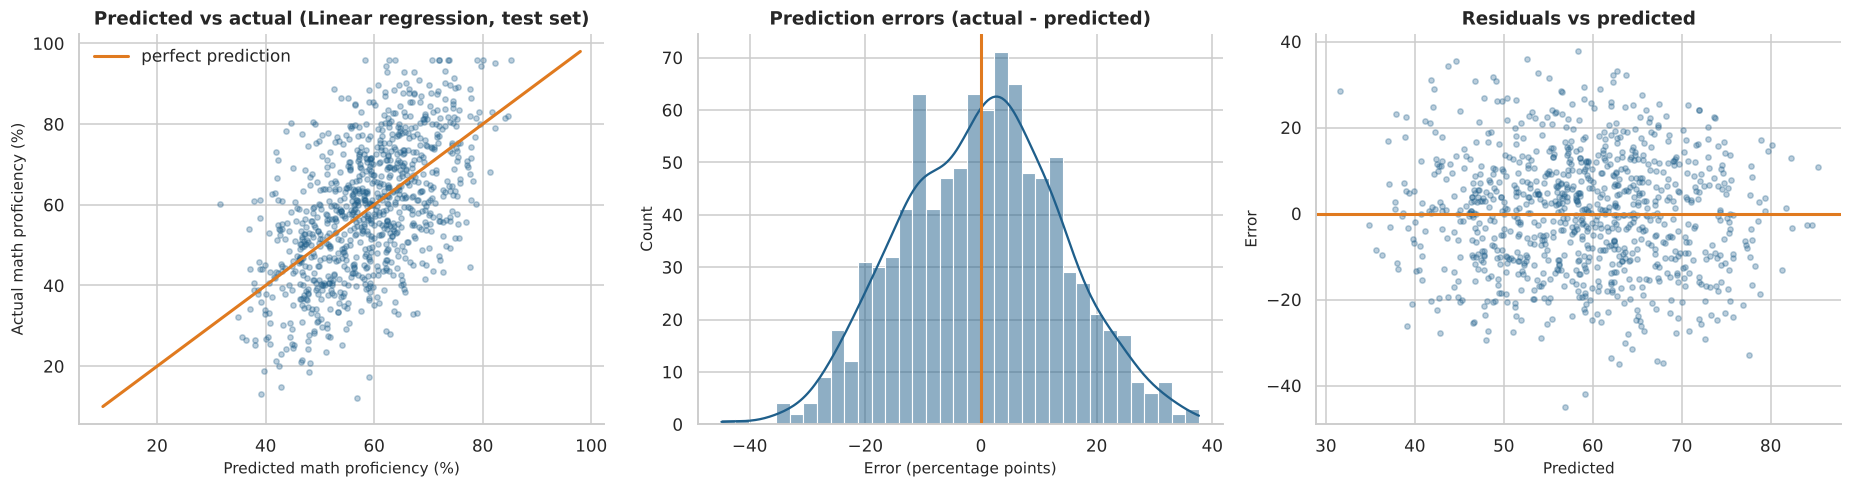

Share of test schools predicted within 5 pts : 28%
Share of test schools predicted within 10 pts: 51%
Share of test schools predicted within 15 pts: 72%
Mean error (bias): 0.12 pts (close to 0 means no systematic over- or under-prediction)


In [13]:
te = k12.loc[X_test.index].copy()
te['pred'] = sel_model.predict(X_test)
te['resid'] = te[TARGET] - te['pred']
te['abs_err'] = te['resid'].abs()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(te['pred'], te[TARGET], alpha=.3, s=12, color=PALETTE['primary'])
lims = [min(te['pred'].min(), te[TARGET].min()) - 2, max(te['pred'].max(), te[TARGET].max()) + 2]
ax[0].plot(lims, lims, color=PALETTE['accent'], lw=2, label='perfect prediction')
ax[0].set_xlabel('Predicted math proficiency (%)'); ax[0].set_ylabel('Actual math proficiency (%)')
ax[0].set_title(f'Predicted vs actual ({selected}, test set)'); ax[0].legend(frameon=False)
sns.histplot(te['resid'], bins=35, kde=True, ax=ax[1], color=PALETTE['primary'])
ax[1].axvline(0, color=PALETTE['accent'], lw=2); ax[1].set_title('Prediction errors (actual - predicted)'); ax[1].set_xlabel('Error (percentage points)')
ax[2].scatter(te['pred'], te['resid'], alpha=.3, s=12, color=PALETTE['primary']); ax[2].axhline(0, color=PALETTE['accent'], lw=2)
ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('Error'); ax[2].set_title('Residuals vs predicted')
plt.tight_layout(); save_fig('05_error_analysis'); plt.show()

within5 = (te['abs_err'] <= 5).mean(); within10 = (te['abs_err'] <= 10).mean(); within15 = (te['abs_err'] <= 15).mean()
print(f'Share of test schools predicted within 5 pts : {within5:.0%}')
print(f'Share of test schools predicted within 10 pts: {within10:.0%}')
print(f'Share of test schools predicted within 15 pts: {within15:.0%}')
print(f'Mean error (bias): {te["resid"].mean():.2f} pts (close to 0 means no systematic over- or under-prediction)')

In [14]:
group_tbl = pd.concat({
    'poverty group': te.groupby('poverty_tertile', observed=True).agg(n=('abs_err', 'size'), MAE=('abs_err', 'mean'), bias=('resid', 'mean')),
    'level': te.groupby('level').agg(n=('abs_err', 'size'), MAE=('abs_err', 'mean'), bias=('resid', 'mean')),
    'control': te.groupby('control').agg(n=('abs_err', 'size'), MAE=('abs_err', 'mean'), bias=('resid', 'mean')),
}).round(2)
group_tbl

n    MAE  bias
poverty group Low poverty         322  11.29 -0.40
              Mid poverty         307  11.03  0.61
              High poverty        300  10.83  0.18
level         Elementary School   458  11.48  0.73
              High School         243  10.80 -0.28
              K-12 Combined        36  10.61 -4.87
              Middle School       192  10.45  0.11
control       Private For-Profit   21  10.48  2.18
              Private Non-Profit   70  10.58 -1.94
              Private Religious    55  11.53 -1.42
              Public              658  11.28  0.75
              Public Charter      125  10.02 -1.70

**Reading the error analysis.**
- The errors are centred on zero and roughly bell-shaped, so there is no systematic over- or under-prediction overall.
- The average error (MAE) is similar across poverty groups and school levels (roughly 10.5 to 11.5 points), so the model is not noticeably worse for the schools that matter most (high-poverty ones). Groups with few test rows (K-12 Combined has 36, private for-profit 21) have noisy estimates, so I do not over-read their larger biases.
- The model is **modest at the level of an individual school**: only about half of unseen schools are predicted within 10 points, and about 28% within 5 points. That is a real limit. It means the model is useful for *understanding which factors matter and for broad screening*, and should never be used as an automatic verdict on a single school.

## 8. Interpretation: what did the model learn?

Predictive accuracy is not understanding. I examine the model in three complementary ways, and I stay careful: these tools reveal what the model **relies on to predict**, not what *causes* scores to change.

### 8.1 Linear model coefficients (standardised)
Numeric features are on a common scale (1 sd), so coefficient sizes are comparable: "points of math proficiency per 1 sd change in the feature".

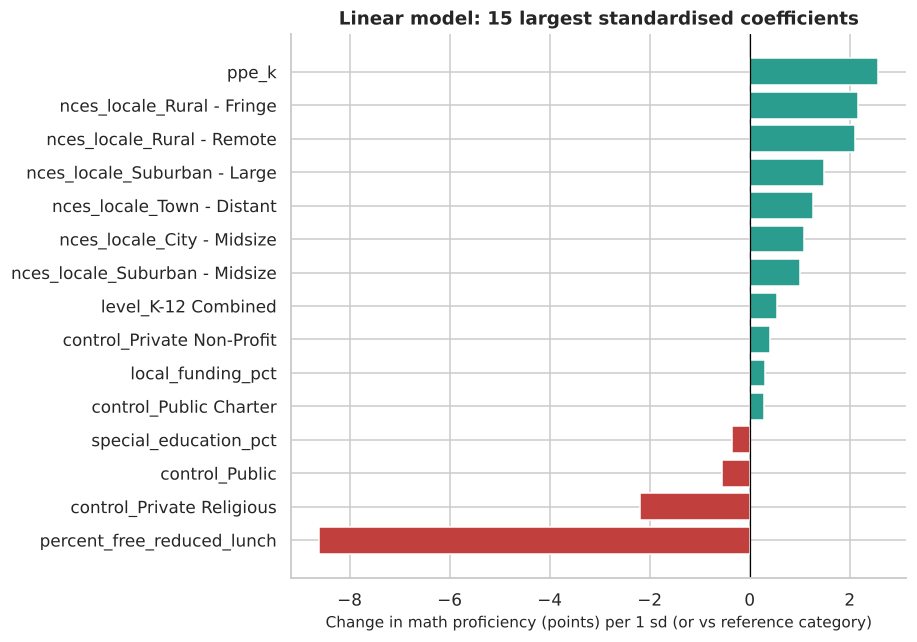

,coefficient
percent_free_reduced_lunch,-8.61
ppe_k,2.57
control_Private Religious,-2.19
nces_locale_Rural - Fringe,2.17
nces_locale_Rural - Remote,2.10
nces_locale_Suburban - Large,1.49
nces_locale_Town - Distant,1.26
nces_locale_City - Midsize,1.09
nces_locale_Suburban - Midsize,1.00
control_Public,-0.56


In [15]:
lin = models['Linear regression']
names = lin.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(lin.named_steps['model'].coef_, index=names).sort_values()
coefs.index = [c.replace('num__', '').replace('cat__', '') for c in coefs.index]
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(15).index).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index, top.values, color=[PALETTE['bad'] if v < 0 else PALETTE['good'] for v in top.values])
ax.axvline(0, color='black', lw=.8)
ax.set_title('Linear model: 15 largest standardised coefficients'); ax.set_xlabel('Change in math proficiency (points) per 1 sd (or vs reference category)')
plt.tight_layout(); save_fig('05_linear_coefficients'); plt.show()
display(coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index).round(2).to_frame('coefficient'))

**Reading the coefficients.** Two features dominate: poverty (strongly negative, by far the largest) and per-pupil spending (positive). The locale and control coefficients are small, and the permutation importance below shows they do not improve predictions on unseen schools, so I treat them as noise rather than as real effects.

**A note on overlapping features.** Title I "Not Applicable" coincides exactly with private control, and the funding shares are fixed for private non-profit and religious schools. When features overlap like this, a linear fit cannot tell which of them "owns" the shared signal, so their individual coefficients are not separately identifiable. Do not read the control, Title I or funding-share coefficients one by one; the poverty and spending coefficients (which do not have this problem) are the ones to interpret.

### 8.2 Permutation importance
Randomly shuffle one feature in the *test* set and measure how much the model's error rises. A feature the model leans on causes a big increase; an irrelevant feature causes none. Because I shuffle the **original** columns (before one-hot encoding), the importance of a categorical feature appears as a single bar. I compute it for the simple linear model **and** the flexible gradient boosting model: if both rely on the same features, the conclusion is not model-specific.

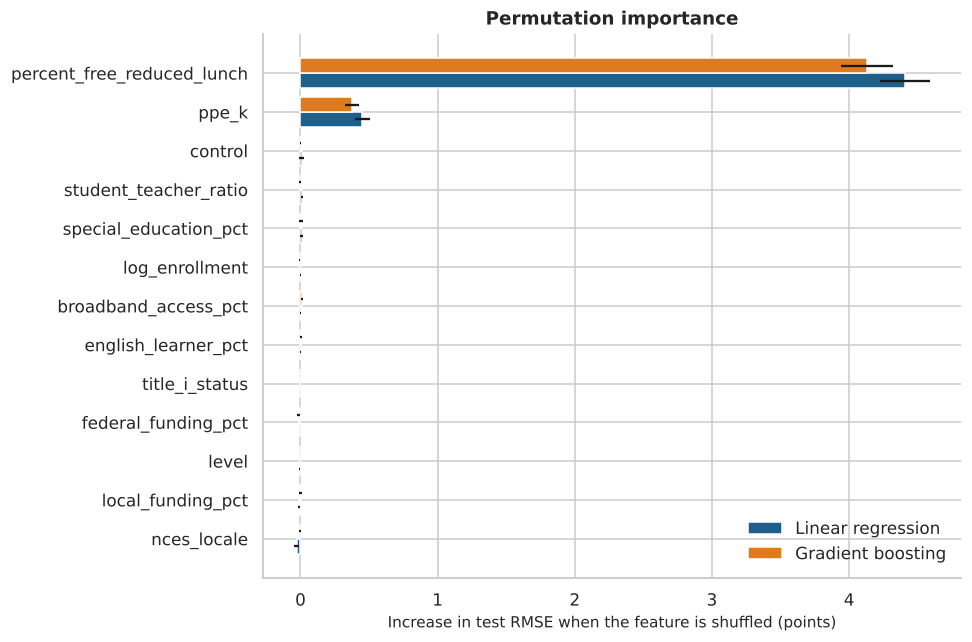

,linear,gradient_boosting
percent_free_reduced_lunch,4.407,4.131
ppe_k,0.452,0.373
control,0.011,-0.001
student_teacher_ratio,0.010,-0.002
special_education_pct,0.009,0.002
log_enrollment,-0.000,-0.005
broadband_access_pct,-0.000,0.008
english_learner_pct,-0.001,0.006
title_i_status,-0.001,-0.001
federal_funding_pct,-0.001,-0.014


In [16]:
def perm(model):
    r = permutation_importance(model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
                               scoring='neg_root_mean_squared_error', n_jobs=1)
    return pd.DataFrame({'importance': r.importances_mean, 'sd': r.importances_std}, index=X_test.columns)

perm_lin = perm(models['Linear regression'])
perm_gb = perm(models['Gradient boosting'])

order = perm_lin['importance'].sort_values().index
fig, ax = plt.subplots(figsize=(9, 6))
h = 0.38; ypos = np.arange(len(order))
ax.barh(ypos - h / 2, perm_lin.loc[order, 'importance'], h, xerr=perm_lin.loc[order, 'sd'], label='Linear regression', color=PALETTE['primary'])
ax.barh(ypos + h / 2, perm_gb.loc[order, 'importance'], h, xerr=perm_gb.loc[order, 'sd'], label='Gradient boosting', color=PALETTE['accent'])
ax.set_yticks(ypos); ax.set_yticklabels(order)
ax.set_xlabel('Increase in test RMSE when the feature is shuffled (points)'); ax.set_title('Permutation importance')
ax.legend(frameon=False)
plt.tight_layout(); save_fig('05_permutation_importance'); plt.show()

comp = pd.concat([perm_lin['importance'].rename('linear'), perm_gb['importance'].rename('gradient_boosting')], axis=1).sort_values('linear', ascending=False)
display(comp.round(3))

**Reading the importance results.** Poverty (free/reduced lunch) is by far the feature the models rely on most, in *both* models. Per-pupil spending comes next. Everything else (broadband, staffing, school size, funding mix, level, locale, Title I) adds little or nothing. This reproduces the finding of the statistical notebook with a completely different method: **poverty first, spending second, and broadband contributes almost nothing once poverty is known.**

Two cautions. (1) Permutation importance splits credit among correlated features: Title I status and the federal-funding share are largely echoes of poverty, so their small scores partly reflect "poverty already covers it". (2) Importance is about *prediction*, not cause.

### 8.3 Partial dependence: the shape of each relationship
Partial dependence shows the average predicted math proficiency as one feature varies, holding the others at their observed values. Overlaying the linear and gradient boosting models shows whether the flexible model discovered any curves the linear model missed.

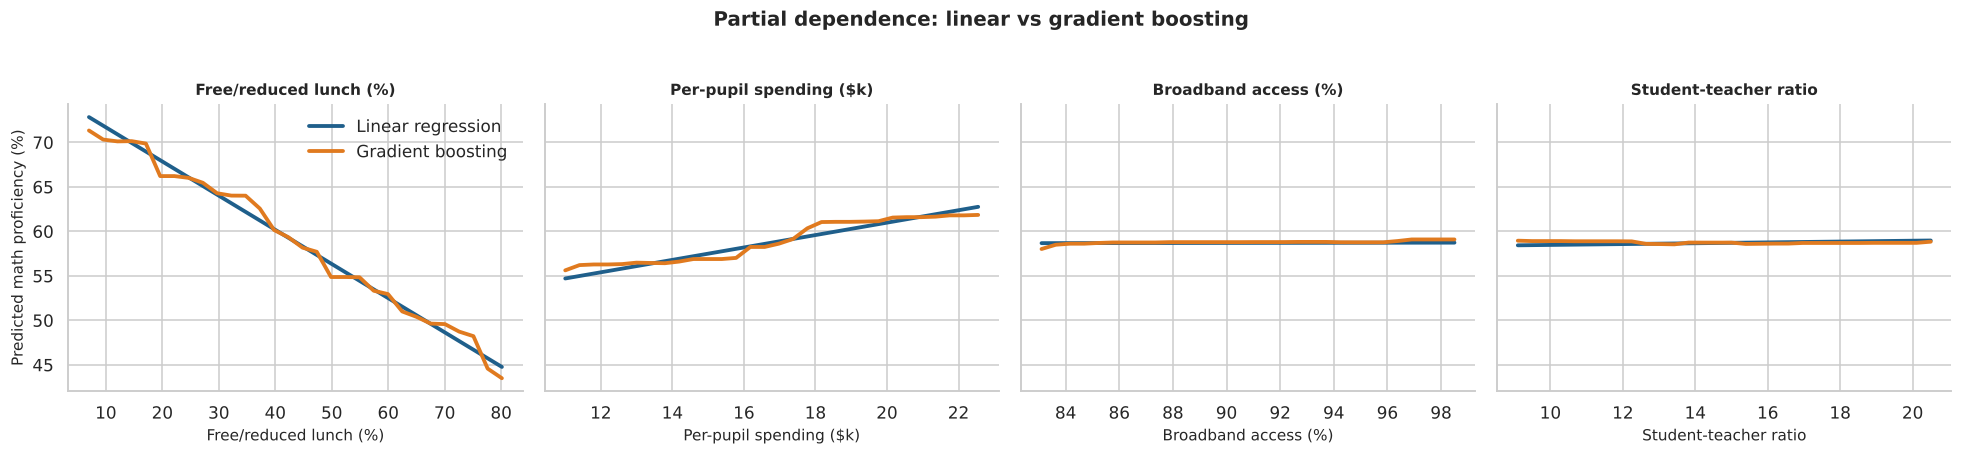

In [17]:
pdp_feats = {'percent_free_reduced_lunch': 'Free/reduced lunch (%)', 'ppe_k': 'Per-pupil spending ($k)',
             'broadband_access_pct': 'Broadband access (%)', 'student_teacher_ratio': 'Student-teacher ratio'}
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (f, lab) in zip(axes, pdp_feats.items()):
    for nm, col in [('Linear regression', PALETTE['primary']), ('Gradient boosting', PALETTE['accent'])]:
        pdp = partial_dependence(models[nm], X_test, [f], kind='average', grid_resolution=30)
        ax.plot(pdp['grid_values'][0], pdp['average'][0], lw=2.5, label=nm, color=col)
    ax.set_xlabel(lab); ax.set_title(lab, fontsize=10)
axes[0].set_ylabel('Predicted math proficiency (%)'); axes[0].legend(frameon=False)
plt.suptitle('Partial dependence: linear vs gradient boosting', y=1.03, fontsize=13, fontweight='bold')
plt.tight_layout(); save_fig('05_partial_dependence'); plt.show()

**Reading the partial-dependence plots.** The poverty curve slopes steeply downward and the spending curve slopes gently upward, while the broadband and staffing curves are nearly flat. The gradient boosting curve closely follows the straight linear one, so there is **no hidden non-linearity** being missed, and no sign of a "threshold" (for example, spending only mattering above a certain level) within the range of this data.

## 9. Ablation: which feature groups add predictive value?
Starting from poverty alone, I add one group of features at a time (5-fold cross-validated linear model on the training set) and track the gain in R². This is the machine-learning version of the nested regression in notebook 04. The last row adds racial composition as a **sensitivity check only** (it is not in the main model).

,CV_R2,CV_RMSE,R2_gain
feature set,,,
Poverty only,0.3587,12.7584,NaN
+ Per-pupil spending,0.3829,12.5155,0.0242
+ Broadband,0.3823,12.5213,-0.0006
+ Staffing & size,0.3820,12.5245,-0.0003
"+ Student needs (EL, special ed)",0.3820,12.5239,0.0001
+ Funding mix,0.3813,12.5313,-0.0007
"+ School context (level, control, locale, Title I)",0.3786,12.5588,-0.0027
+ Racial composition (sensitivity only),0.3775,12.5695,-0.0011


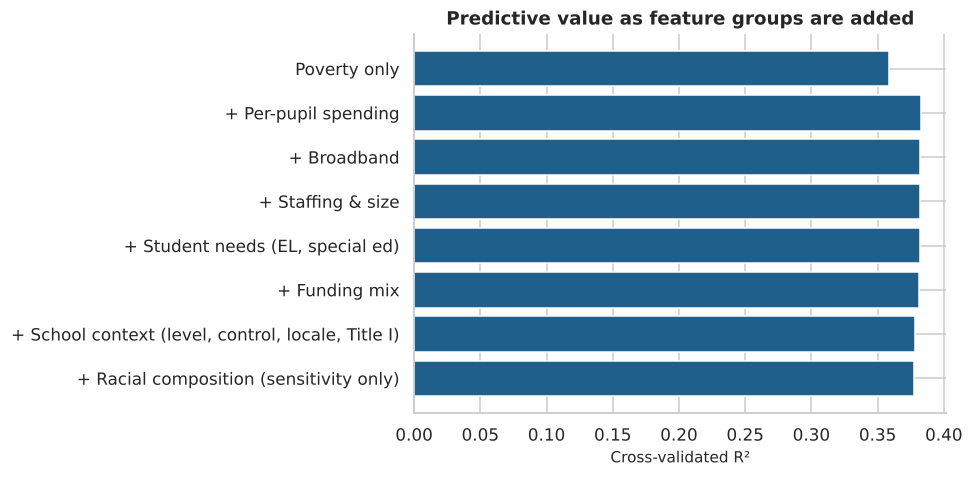

In [18]:
race = ['racial_black_pct', 'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct', 'racial_two_or_more_pct']
steps = [
    ('Poverty only', ['percent_free_reduced_lunch'], []),
    ('+ Per-pupil spending', ['ppe_k'], []),
    ('+ Broadband', ['broadband_access_pct'], []),
    ('+ Staffing & size', ['student_teacher_ratio', 'log_enrollment'], []),
    ('+ Student needs (EL, special ed)', ['english_learner_pct', 'special_education_pct'], []),
    ('+ Funding mix', ['federal_funding_pct', 'local_funding_pct'], []),
    ('+ School context (level, control, locale, Title I)', [], cat_features),
    ('+ Racial composition (sensitivity only)', race, []),
]
train_full = k12.loc[X_train.index]
cur_num, cur_cat, rows = [], [], []
for label, add_num, add_cat in steps:
    cur_num += add_num; cur_cat += add_cat
    pre = ColumnTransformer([('num', StandardScaler(), cur_num), ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cur_cat)])
    pipe = Pipeline([('pre', pre), ('model', LinearRegression())])
    res = cross_validate(pipe, train_full[cur_num + cur_cat], y_train, cv=cv_outer, scoring=scoring, n_jobs=1)
    rows.append({'feature set': label, 'CV_R2': res['test_r2'].mean(), 'CV_RMSE': -res['test_rmse'].mean()})
ablation = pd.DataFrame(rows).set_index('feature set')
ablation['R2_gain'] = ablation['CV_R2'].diff()
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ablation.index[::-1], ablation['CV_R2'][::-1], color=PALETTE['primary'])
ax.set_xlabel('Cross-validated R²'); ax.set_title('Predictive value as feature groups are added')
plt.tight_layout(); save_fig('05_ablation'); plt.show()

**Reading the ablation.** Poverty alone delivers most of the achievable R². Adding spending produces the one other clearly visible gain. Every later group (broadband, staffing, student needs, funding mix, school context) adds almost nothing, and the sensitivity check shows racial composition adds essentially no predictive value beyond the economic variables. This is why leaving it out of the main model costs nothing in accuracy while avoiding a fairness problem.

## 10. Summary and limitations

In [19]:
sel_t = test_rows[selected]
imp = comp['linear'].sort_values(ascending=False)
print('=== MACHINE LEARNING SUMMARY (computed above) ===\n')
print(f"Selected model        : {selected} (simplest model within 1 SE of the best CV RMSE)")
print(f"Headline R² (repeated CV): {headline['repeated_cv_r2_mean']:.3f} (sd {headline['repeated_cv_r2_sd']:.3f})")
print(f"Seed-42 test R²       : {sel_t['R2']:.3f}  | Test RMSE: {sel_t['RMSE']:.2f} pts | Test MAE: {sel_t['MAE']:.2f} pts")
print(f"Baseline (mean) RMSE  : {test_rows['Baseline (mean)']['RMSE']:.2f} pts")
print(f"Best flexible model   : Gradient boosting test R² = {test_rows['Gradient boosting']['R2']:.3f}; Random forest = {test_rows['Random forest']['R2']:.3f}")
print(f"Top predictors        : {', '.join(imp.index[:3])}")
print(f"Within 10 points      : {within10:.0%} of unseen schools")

ml_results = {
    'selected_model': selected,
    'features': {'numeric': num_features, 'categorical': cat_features},
    'best_params': {k: {a: (b if not isinstance(b, (np.integer, np.floating)) else float(b)) for a, b in v.items()} for k, v in best_params.items()},
    'cv_table': cv_tbl.reset_index().rename(columns={'index': 'model'}).to_dict('records'),
    'test_table': test_tbl.drop(columns='selected').reset_index().rename(columns={'index': 'model'}).to_dict('records'),
    'headline': headline,
    'selected_test': sel_t,
    'baseline_test': test_rows['Baseline (mean)'],
    'test_ci': test_ci,
    'within5': float(within5), 'within10': float(within10), 'within15': float(within15),
    'perm_importance_linear': perm_lin['importance'].to_dict(),
    'perm_importance_gb': perm_gb['importance'].to_dict(),
    'linear_coefficients_top': coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index).to_dict(),
    'ablation': ablation.reset_index().to_dict('records'),
    'n_train': len(X_train), 'n_test': len(X_test),
}
save_json(ml_results, 'ml_results')
print('\nSaved reports/results/ml_results.json for notebook 06.')

=== MACHINE LEARNING SUMMARY (computed above) ===

Selected model        : Linear regression (simplest model within 1 SE of the best CV RMSE)
Headline R² (repeated CV): 0.363 (sd 0.028)
Seed-42 test R²       : 0.308  | Test RMSE: 13.70 pts | Test MAE: 11.06 pts
Baseline (mean) RMSE  : 16.47 pts
Best flexible model   : Gradient boosting test R² = 0.304; Random forest = 0.298
Top predictors        : percent_free_reduced_lunch, ppe_k, control
Within 10 points      : 51% of unseen schools

Saved reports/results/ml_results.json for notebook 06.


### Limitations of the ML component
- **Accuracy ceiling.** The model explains a moderate share of the variation in math proficiency. A large part of school-to-school difference is **not in the data** (instruction quality, curriculum, prior achievement, local context). More complex algorithms do not fix missing information.
- **Association, not causation.** Importance and partial dependence describe what the model *uses to predict*. They do not show that changing a feature would change scores.
- **Cross-sectional, single snapshot.** The model predicts scores for schools like those in this file; it says nothing about how a school's score would change over time if its resources changed.
- **Possible clustering.** Schools in the same district or state may share unmeasured influences, so the held-out test could be slightly optimistic for completely new regions.
- **Ceiling values.** Proficiency capped at 96% slightly compresses predictions at the top end.
- **Fairness.** Even though racial composition was excluded, poverty is correlated with race in the real world, so any use of the model to allocate resources should be audited for disparate impact.

**Next → `06_insights_and_recommendations.ipynb`:** translate the statistical and ML evidence into stakeholder-ready insights and recommendations.